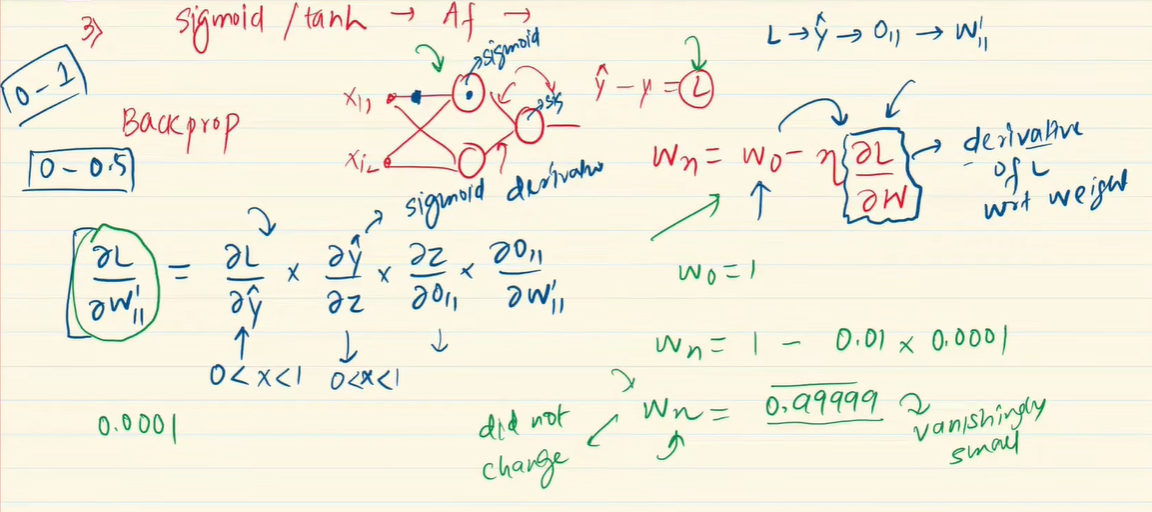

Vanishing Gradient Problem হলো এমন একটি সমস্যা, যেখানে Backpropagation করার সময় Gradient ধীরে ধীরে এত ছোট হয়ে যায় যে Neural Network-এর প্রথম দিকের Layers-গুলোর Weight এবং Bias কার্যকরভাবে Update হতে পারে না।

1. প্রথমে Gradient কী মনে করি?
Backpropagation-এর সময় আমরা Loss Function থেকে Gradient calculate করি।

Gradient আমাদের বলে:
- কোন দিকে Weight পরিবর্তন করতে হবে।
- কতটুকু Weight পরিবর্তন করতে হবে।

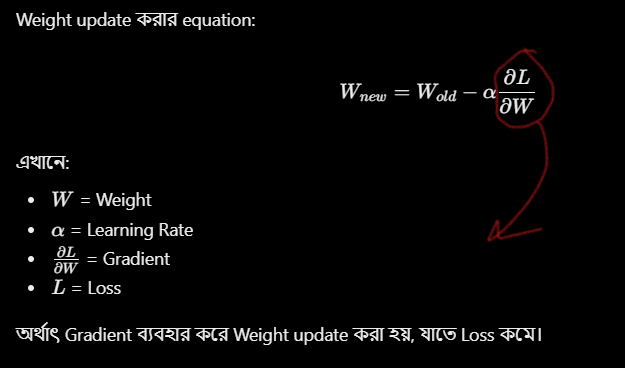

2. Vanishing Gradient Problem কীভাবে হয়?

Backpropagation শুরু হয় Output Layer থেকে এবং ধীরে ধীরে Hidden Layer হয়ে Input Layer-এর দিকে যায়।
এই সময় Chain Rule ব্যবহার করে Gradient calculate হয়।
ধরো, প্রতিটি Layer-এর Gradient Multiplication-এর কারণে ছোট হতে থাকে।
একটি উদাহরণ দেখি:

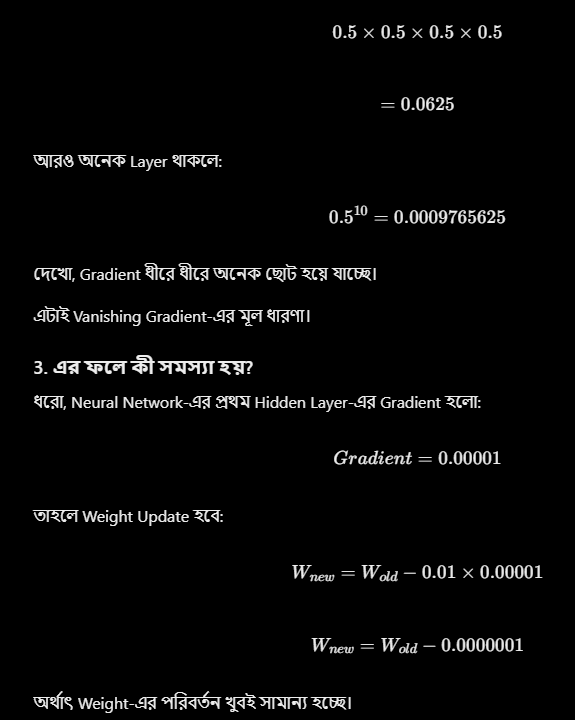
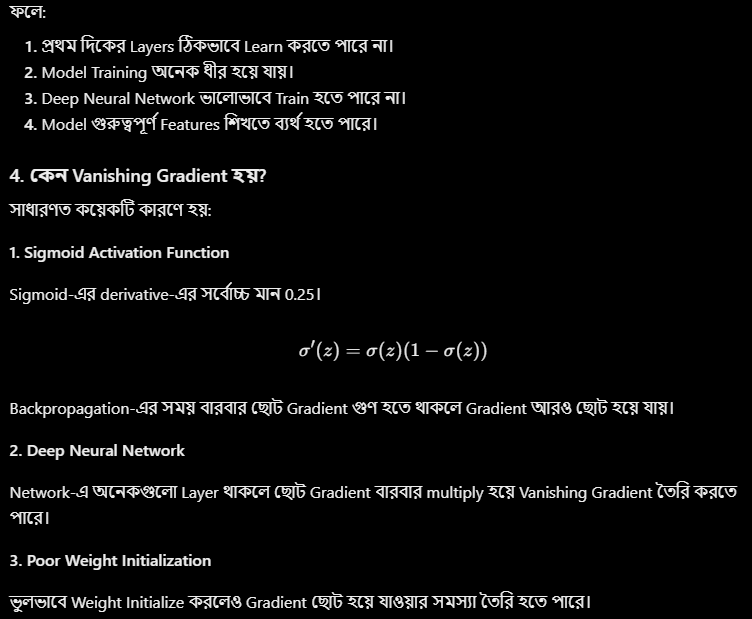

# how to recognize that amar vanishing gradient problem hocche?

1. focues on loass - jodi epoch e loss changes na hoy 
2. weight er akta graph plot kore dekh. suppose jekono akta weight nibo W11 hote pare. tar (value vs epoch) plot korbo
jodi consistant hoy, tahole bujbo vanishing gradient problem ase

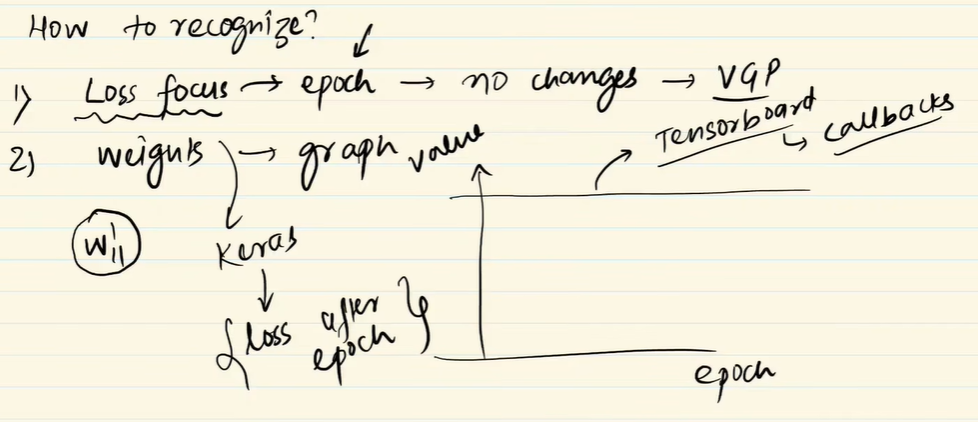

In [56]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dense, Input
from keras.models import Sequential

In [57]:
X,y = make_moons(n_samples=250, noise=0.05, random_state=42)

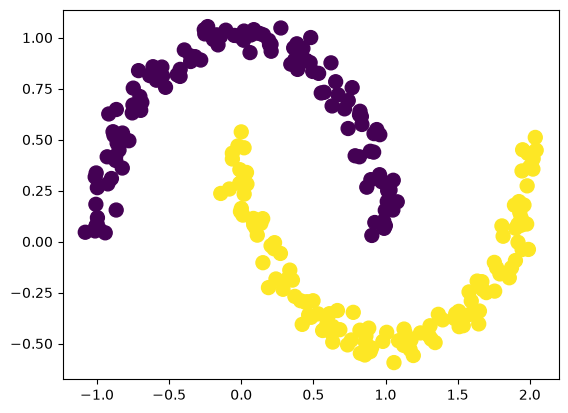

In [58]:
plt.scatter(X[:,0],X[:,1], c=y,s=100)

In [59]:
model = Sequential()

In [60]:
model.add(Input(shape=(2,)))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

# Note: classification problem hole: sob jaigai activation function onno kisu use korleo, last output layer e "Sigmoid" use kortei hobe

In [61]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_33 (Dense)                │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,031 (4.03 KB)

 Trainable params: 1,031 (4.03 KB)

 Non-trainable params: 0 (0.00 B)

# কিছু Common Loss Functions-এর নাম নিচে দিলাম:
1. MSE (Mean Squared Error)
2. MAE (Mean Absolute Error)
3. Binary Cross-Entropy (BCE)
4. Categorical Cross-Entropy (CCE)
5. Sparse Categorical Cross-Entropy
6. Hinge Loss
7. Huber Loss
8. Log-Cosh Loss
9. Kullback-Leibler (KL) Divergence
10. Poisson Loss

মনে রাখবে:
- Regression → MSE, MAE, Huber Loss, Log-Cosh Loss
- Binary Classification → Binary Cross-Entropy
- Multi-class Classification → Categorical Cross-Entropy, Sparse Categorical Cross-Entropy
- SVM classification - Hinge Loss

In [62]:
model.compile(loss='binary_crossentropy', optimizer="adam", metrics=['accuracy'])

In [63]:
old_weights = model.get_weights()[0] # W11 ber korlam

In [64]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [65]:
model.fit(X_train,y_train, epochs=100)

Epoch 1/100


7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.5050 - loss: 0.6938
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6200 - loss: 0.6920 
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8100 - loss: 0.6898 
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9500 - loss: 0.6867 
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9200 - loss: 0.6822 
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9250 - loss: 0.6755 
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8800 - loss: 0.6659 
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9300 - loss: 0.6518 
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9150 - loss: 0.6349 
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9200 - loss: 0.6157 
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9050 - loss: 0.5902 
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9100 - loss: 0.5608  
E

In [66]:
new_weight = model.get_weights()[0]

# see the learning rate, model koto use korse

In [67]:
model.optimizer.get_config()['learning_rate']

0.0010000000474974513

# to find the gradient 

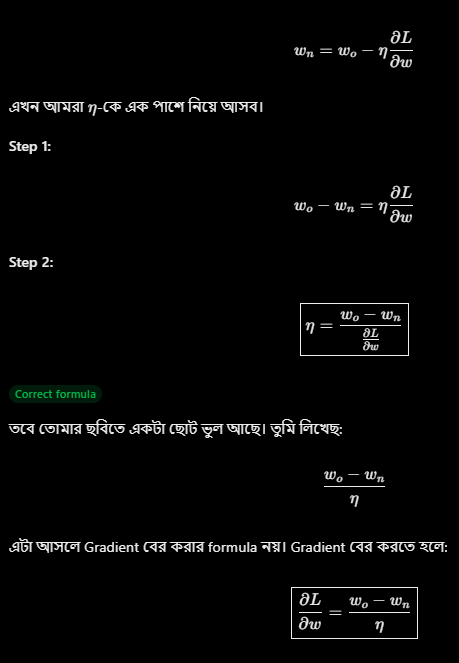

In [68]:
gradient = (old_weights - new_weight)/0.001
percant_change = abs(100*(old_weights - new_weight)/old_weights)

In [69]:
gradient

array([[ 252.82817 , -192.14247 ,   62.834053,   60.39625 ,  -93.59282 ,
         257.4214  , -128.80812 , -144.1744  ,   10.567501,  270.18723 ],
       [ -76.940025,  -86.81775 , -148.44064 , -102.08949 ,  115.62174 ,
        -133.16066 ,  -34.47181 ,   32.73077 , -123.89832 ,  -91.81728 ]],
      dtype=float32)

In [70]:
percant_change

array([[ 46.187107 , 143.14375  ,  12.451641 ,  16.970314 ,  15.190616 ,
        338.0756   , 217.30304  ,  21.37345  ,   4.1736336,  68.50397  ],
       [ 25.746065 , 228.71289  , 120.26034  ,  34.240807 ,  22.405046 ,
        122.89047  ,   7.3327117,  19.798815 ,  17.5322   , 164.24022  ]],
      dtype=float32)

In [71]:
old_weights

array([[-0.5473999 ,  0.13423043,  0.50462466,  0.35589355,  0.61612266,
        -0.07614315,  0.05927581,  0.67454904,  0.25319666, -0.39441106],
       [ 0.2988419 ,  0.03795928, -0.12343276,  0.29815155, -0.51605225,
         0.10835719,  0.47011   ,  0.16531682,  0.70669013,  0.05590427]],
      dtype=float32)

In [72]:
new_weight

array([[-0.80022806,  0.32637292,  0.4417906 ,  0.2954973 ,  0.7097155 ,
        -0.33356455,  0.18808393,  0.81872344,  0.24262916, -0.6645983 ],
       [ 0.37578192,  0.12477703,  0.02500789,  0.40024105, -0.631674  ,
         0.24151786,  0.5045818 ,  0.13258605,  0.83058846,  0.14772156]],
      dtype=float32)

# how to solve vanishing gradient problem
1. reduce model complexity
   - deep neural network er jaigai shallow neural network use korbo . ete derivative er number tmn boro hobe na. numner of derivative kom hobe. vanishing gradient er change kom hobe
Note: but eita tmn kaj er na

2. Using ReLu(Rectified Linear Unit) Activation functions

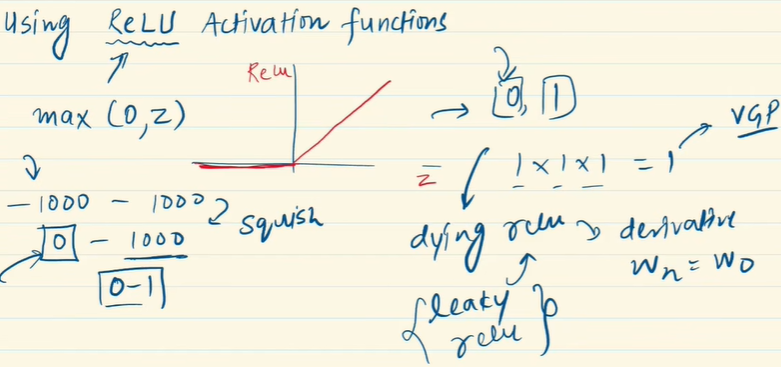

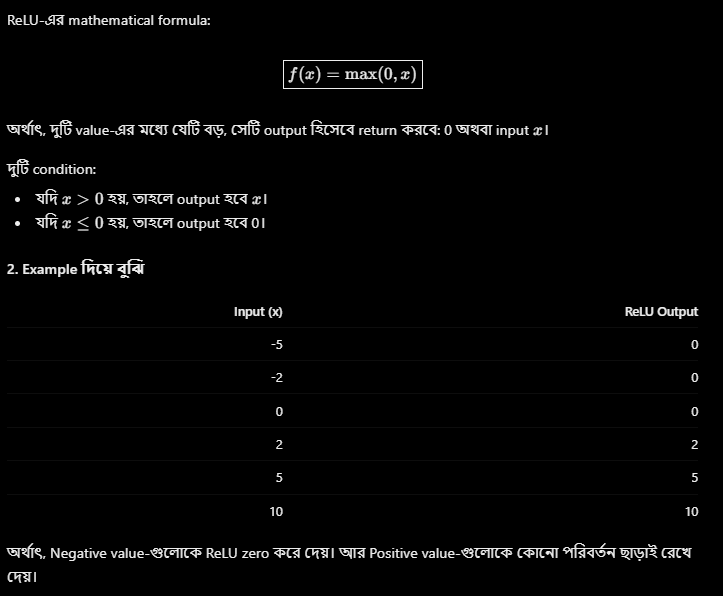

Note: relu te akta problem hocche: activation 0 hole new_weight = old_weight soman hoy, ete weight update hoyna

3. proper weight initialization: proper weight initialization er maddhome ei problem solve kora jai. er jonno kisu technique ase. like
   1. Glorat
   2. Xavior

4. Batch normalization: er maddomeo vanishing gradient problem solve kora jai. eita ak type er layer
5. Residual network: eita ak special building blocks, jeita ANN use kora hoy

# Exploding Greadient Problem
- eita vanishing problem er ulta: vanishng gradient problem derivative er calculation onk choto hoy sigmoid er jonno jar jonno weight update ak porjaiye hoy na.
- and Exploding Gradient হলো Deep Learning-এর একটি সমস্যা, যেখানে Backpropagation করার সময় gradient-এর মান অনেক বড় হয়ে যায়। ফলে Weight Update অনেক বেশি হয়ে যায় এবং Model-এর learning unstable হয়ে পড়ে।

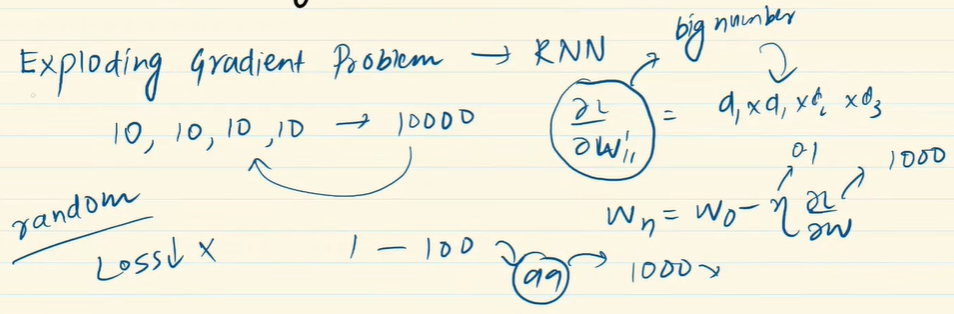

Note: eita solve korar jonno: gradient clipping technique use kori